# RQ1 (OULAD): frequency, intensity and regularity as predictors of course outcome
Revised analysis. Population: Pass/Distinction vs Fail (Withdrawn excluded, because withdrawal cuts activity short and would make low frequency/regularity true by construction).
Changes from the first version: predictors standardised inside each CV fold; log-gap robustness model; univariate vs adjusted odds ratios and VIFs; pass rate by gap **within** frequency quintiles; weekly trajectories that count inactive weeks as zero and stop at week 33 (shortest presentation).

In [1]:
import pandas as pd, numpy as np, zipfile
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score
with zipfile.ZipFile('archive.zip') as z:
    vle=pd.read_csv(z.open('studentVle.csv'),usecols=['code_module','code_presentation','id_student','date','sum_click'])
    info=pd.read_csv(z.open('studentInfo.csv')); courses=pd.read_csv(z.open('courses.csv'))
print(info.final_result.value_counts())
print('Presentation length range:',courses.module_presentation_length.min(),'-',courses.module_presentation_length.max(),'days')

final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64
Presentation length range: 234 - 269 days


In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
C=['#2a78d6','#eb6834','#1baf7a','#eda100']
INK='#0b0b0b'; INK2='#52514e'; GRID='#e4e3de'; SURF='#ffffff'
mpl.rcParams.update({'font.family':'DejaVu Sans','font.size':7,'axes.edgecolor':GRID,'axes.labelcolor':INK2,'xtick.color':INK2,'ytick.color':INK2,
 'axes.grid':True,'grid.color':GRID,'grid.linewidth':0.8,'axes.spines.top':False,'axes.spines.right':False,'axes.titlesize':7.5,'axes.titlecolor':INK,
 'axes.titleweight':'bold','axes.titlelocation':'left','lines.linewidth':1.5,'lines.solid_capstyle':'round','legend.frameon':False,'figure.dpi':200,'savefig.dpi':200,
 'savefig.bbox':'tight','figure.facecolor':SURF,'axes.facecolor':SURF,'xtick.major.size':0,'ytick.major.size':0,'legend.fontsize':6.8})

import os, pandas as pd; os.makedirs('figures',exist_ok=True); pd.set_option('display.width',220); pd.set_option('display.max_columns',30)

## 1. Features

In [3]:
keys=['id_student','code_module','code_presentation']
h=info[info.final_result.isin(['Pass','Distinction','Fail'])].copy()
h['outcome']=h.final_result.isin(['Pass','Distinction']).astype(int)
v=vle.merge(h[keys],on=keys)
daily=v.groupby(keys+['date']).sum_click.sum().reset_index().sort_values(keys+['date'])
daily['gap']=daily.groupby(keys).date.diff()
f=(daily.groupby(keys).agg(active_days=('date','nunique'),clicks=('sum_click','sum'),median_active_day_gap=('gap','median'),last_day=('date','max'))
   .reset_index().merge(courses,on=['code_module','code_presentation']))
f['frequency']=f.active_days/(f.module_presentation_length/7)
f['intensity']=np.log1p(f.clicks/f.active_days)
f['regularity']=-f.median_active_day_gap
a=f.merge(h[keys+['outcome']],on=keys).dropna(subset=['frequency','intensity','regularity']).reset_index(drop=True)
print('Records:',len(a),'| learners:',a.id_student.nunique(),'| Pass/Distinction base rate:',round(a.outcome.mean(),3))

Records: 21832 | learners: 20547 | Pass/Distinction base rate: 0.704


## 2. Cross-validated models (5-fold GroupKFold by learner, scaling fitted inside each fold)

In [4]:
y=a.outcome.values; g=a.id_student.values; cv=GroupKFold(n_splits=5)
a['log_regularity']=-np.log(a.median_active_day_gap)
def cv_auc(make,cols):
    out=[]
    for tr,te in cv.split(a,y,g):
        sc=StandardScaler().fit(a.iloc[tr][cols])
        m=make().fit(sc.transform(a.iloc[tr][cols]),y[tr])
        out.append(roc_auc_score(y[te],m.predict_proba(sc.transform(a.iloc[te][cols]))[:,1]))
    return np.array(out)
LR=lambda: LogisticRegression(max_iter=1000)
DT=lambda: DecisionTreeClassifier(max_depth=5,random_state=42,class_weight='balanced')
rows=[]
for name,make,reg in [('Logistic Regression (gap in days)',LR,'regularity'),('Logistic Regression (log of gap)',LR,'log_regularity'),('Decision Tree (depth 5)',DT,'regularity')]:
    m1=cv_auc(make,['frequency','intensity']); m2=cv_auc(make,['frequency','intensity',reg]); d=m2-m1
    rows.append([name,f'{m1.mean():.4f} ± {m1.std(ddof=1):.4f}',f'{m2.mean():.4f} ± {m2.std(ddof=1):.4f}',f'{d.mean():+.4f} ± {d.std(ddof=1):.4f}',int((d>0).sum())])
print(pd.DataFrame(rows,columns=['Model','Freq+Int AUC','+Regularity AUC','Gain','Folds with gain']).to_string(index=False))

                            Model    Freq+Int AUC +Regularity AUC             Gain  Folds with gain
Logistic Regression (gap in days) 0.8296 ± 0.0067 0.8312 ± 0.0068 +0.0016 ± 0.0003                5
 Logistic Regression (log of gap) 0.8296 ± 0.0067 0.8479 ± 0.0076 +0.0184 ± 0.0023                5
          Decision Tree (depth 5) 0.8257 ± 0.0069 0.8509 ± 0.0057 +0.0252 ± 0.0058                5


### Choice of tree depth and number of folds

In [5]:
P_=['frequency','intensity','regularity']
for dep in [2,3,5,7,10,None]:
    tr_auc=[]; te=[]
    for tr,ts in cv.split(a,y,g):
        m=DecisionTreeClassifier(max_depth=dep,random_state=42,class_weight='balanced').fit(a.iloc[tr][P_],y[tr])
        te.append(roc_auc_score(y[ts],m.predict_proba(a.iloc[ts][P_])[:,1])); tr_auc.append(roc_auc_score(y[tr],m.predict_proba(a.iloc[tr][P_])[:,1]))
    print(f'depth {dep}: train AUC {np.mean(tr_auc):.3f}, test AUC {np.mean(te):.3f}')
for k_ in [3,5,10]:
    te=[]
    for tr,ts in GroupKFold(k_).split(a,y,g):
        m=DecisionTreeClassifier(max_depth=5,random_state=42,class_weight='balanced').fit(a.iloc[tr][P_],y[tr]); te.append(roc_auc_score(y[ts],m.predict_proba(a.iloc[ts][P_])[:,1]))
    print(f'{k_} folds: test AUC {np.mean(te):.3f} ± {np.std(te,ddof=1):.3f}')
print('Gap skewness raw',round(a.median_active_day_gap.skew(),1),'log',round(np.log(a.median_active_day_gap).skew(),2))

depth 2: train AUC 0.811, test AUC 0.808
depth 3: train AUC 0.836, test AUC 0.833
depth 5: train AUC 0.860, test AUC 0.851
depth 7: train AUC 0.874, test AUC 0.850
depth 10: train AUC 0.906, test AUC 0.814
depth None: train AUC 1.000, test AUC 0.718
3 folds: test AUC 0.852 ± 0.004
5 folds: test AUC 0.851 ± 0.006
10 folds: test AUC 0.851 ± 0.007
Gap skewness raw 15.6 log 1.08


## 3. Why the adjusted regularity coefficient is negative

In [6]:
P=['frequency','intensity','regularity']
Z=StandardScaler().fit_transform(a[P])
uni={c:np.exp(LogisticRegression(max_iter=1000).fit(Z[:,[i]],y).coef_[0][0]) for i,c in enumerate(P)}
adj=dict(zip(P,np.exp(LogisticRegression(max_iter=1000).fit(Z,y).coef_[0])))
def vif(i):
    o=[j for j in range(3) if j!=i]; X=np.c_[np.ones(len(Z)),Z[:,o]]; b=np.linalg.lstsq(X,Z[:,i],rcond=None)[0]
    r2=1-((Z[:,i]-X@b)**2).sum()/((Z[:,i]-Z[:,i].mean())**2).sum(); return 1/(1-r2)
print(pd.DataFrame({'Univariate OR per SD':uni,'Adjusted OR per SD':adj,'VIF':{c:vif(i) for i,c in enumerate(P)}}).round(3))
print('Spearman rho frequency vs median gap:',round(a[['frequency','median_active_day_gap']].corr('spearman').iloc[0,1],3))

            Univariate OR per SD  Adjusted OR per SD    VIF
frequency                  6.097               6.150  1.227
intensity                  1.511               1.088  1.132
regularity                 2.498               0.944  1.143
Spearman rho frequency vs median gap: -0.824


gt             bunched  middle  spread
fq                                    
Least\nactive    0.079   0.313   0.360
2nd              0.411   0.689   0.827
3rd              0.698   0.839   0.871
4th              0.853   0.877   0.911
Most\nactive     0.931   0.957   0.957
gt             bunched  middle  spread
fq                                    
Least\nactive     0.25    0.62    0.72
2nd               0.86    0.91    0.92
3rd               0.93    0.94    0.95
4th               0.96    0.96    0.97
Most\nactive      0.99    0.99    0.99


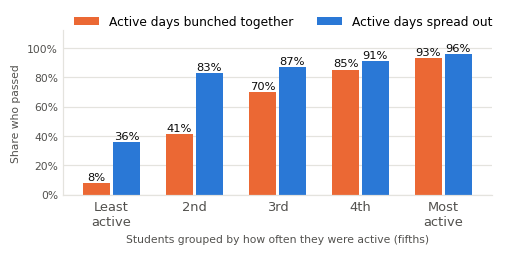

In [7]:
a['last_frac']=a.last_day/a.module_presentation_length
# ---- Figure 3: bars, plain labels
a['fq']=pd.qcut(a.frequency,5,labels=['Least\nactive','2nd','3rd','4th','Most\nactive'])
a['gt']=a.groupby('fq',observed=True).median_active_day_gap.transform(lambda x: pd.qcut(x.rank(method='first'),3,labels=['bunched','middle','spread']))
t3=a.pivot_table(index='fq',columns='gt',values='outcome',aggfunc='mean',observed=True)
fig,ax=plt.subplots(figsize=(4.8,2.4)); x=np.arange(5); w=0.36
for j,(colname,c,lab) in enumerate([('bunched',C[1],'Active days bunched together'),('spread',C[0],'Active days spread out')]):
    b=ax.bar(x+(j-0.5)*w,t3[colname],width=w*0.92,color=c,label=lab)
    for xi,val in zip(x+(j-0.5)*w,t3[colname]): ax.text(xi,val+0.02,f'{val:.0%}',ha='center',fontsize=7.5,color=INK)
ax.set_axisbelow(True); ax.set_xticks(x); ax.set_xticklabels(t3.index,fontsize=8.5); ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0)); ax.set_ylim(0,1.12)
ax.set_ylabel('Share who passed'); ax.set_xlabel('Students grouped by how often they were active (fifths)'); ax.grid(axis='x',visible=False)
ax.legend(loc='upper left',ncol=2,fontsize=8,bbox_to_anchor=(0,1.16))
plt.tight_layout(); plt.savefig('figures/'+'oulad_spread_vs_bunched.png')
print(t3.round(3))
print(a.pivot_table(index='fq',columns='gt',values='last_frac',aggfunc='median',observed=True).round(2))

### Figure 3 robustness: number of frequency groups, and leftover frequency

In [8]:
def bunched_vs_spread(G):
    g_=pd.qcut(a.frequency.rank(method='first'),G,labels=False)
    t_=a.groupby(g_).median_active_day_gap.transform(lambda x: pd.qcut(x.rank(method='first'),3,labels=False))
    d_=a.assign(g=g_,t=t_)[t_!=1]
    return d_.groupby(['g','t']).agg(pass_rate=('outcome','mean'),median_frequency=('frequency','median'),n=('outcome','size')).unstack('t')
for G in [3,5,10]:
    r_=bunched_vs_spread(G); pr=r_['pass_rate']
    print(f'{G} groups | least active: bunched {pr.iloc[0,0]:.0%} vs spread {pr.iloc[0,1]:.0%} | spread higher in all groups: {(pr[2]>pr[0]).all()}')
r5=bunched_vs_spread(5)
print('\nFive groups: median frequency (active days per week) and students per bar')
print(pd.concat({'median_frequency':r5['median_frequency'].round(2),'n':r5['n']},axis=1).rename(columns={0:'bunched',2:'spread'}))

3 groups | least active: bunched 25% vs spread 42% | spread higher in all groups: True
5 groups | least active: bunched 8% vs spread 36% | spread higher in all groups: True
10 groups | least active: bunched 2% vs spread 23% | spread higher in all groups: True

Five groups: median frequency (active days per week) and students per bar
  median_frequency              n       
t          bunched spread bunched spread
g                                       
0             0.43   0.24    1456   1456
1             1.10   0.94    1456   1455
2             1.85   1.60    1456   1455
3             2.82   2.47    1456   1455
4             4.24   4.14    1456   1456


In [9]:
tree=DecisionTreeClassifier(max_depth=5,random_state=42,class_weight='balanced').fit(Z,y)
print(export_text(tree,feature_names=['frequency_z','intensity_z','regularity_z'],max_depth=3))

|--- frequency_z <= -0.58
|   |--- frequency_z <= -1.04
|   |   |--- regularity_z <= -0.54
|   |   |   |--- frequency_z <= -1.18
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- frequency_z >  -1.18
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- regularity_z >  -0.54
|   |   |   |--- frequency_z <= -1.12
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- frequency_z >  -1.12
|   |   |   |   |--- truncated branch of depth 2
|   |--- frequency_z >  -1.04
|   |   |--- regularity_z <= -0.07
|   |   |   |--- frequency_z <= -0.86
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- frequency_z >  -0.86
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- regularity_z >  -0.07
|   |   |   |--- regularity_z <= 0.17
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- regularity_z >  0.17
|   |   |   |   |--- truncated branch of depth 2
|--- frequency_z >  -0.58
|   |--- frequency_z <= 0.19
|   |   |--- regularity

## 4. Weekly trajectories of the three dimensions (inactive weeks count as zero for frequency; weeks 1–33)

     active days                  share active                  regularity                 
grp         Fail Pass/Distinction         Fail Pass/Distinction       Fail Pass/Distinction
week                                                                                       
1           2.10             3.05         0.77             0.87       1.70             1.52
10          1.13             2.50         0.48             0.80       2.73             1.99
20          0.80             2.64         0.33             0.81       2.81             2.04
33          0.39             2.25         0.18             0.76       3.05             2.00


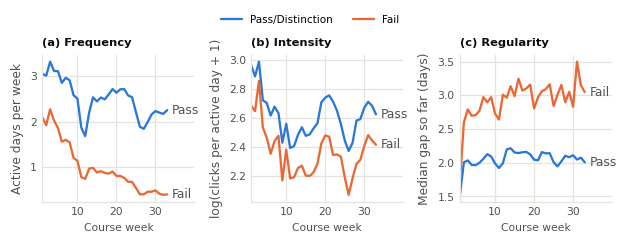

In [10]:
W=33; pop=a[keys+['outcome']]
v2=vle.merge(pop,on=keys); v2=v2[v2.date>=0].copy(); v2['week']=v2.date//7+1
wk=v2[v2.week<=W].groupby(keys+['week']).agg(ad=('date','nunique'),cl=('sum_click','sum')).reset_index()
full=pop.merge(pd.DataFrame({'week':range(1,W+1)}),how='cross').merge(wk,on=keys+['week'],how='left').fillna({'ad':0})
full['grp']=np.where(full.outcome==1,'Pass/Distinction','Fail')
freq=full.groupby(['grp','week']).ad.mean().unstack(0)
share=full.assign(act=full.ad>0).groupby(['grp','week']).act.mean().unstack(0)
act=full[full.ad>0].copy(); act['inten']=np.log1p(act.cl/act.ad); inten=act.groupby(['grp','week']).inten.mean().unstack(0)
dd=v2[v2.week<=W][keys+['date','week']].drop_duplicates().sort_values(keys+['date']); dd['gap']=dd.groupby(keys).date.diff()
dd=dd.dropna(subset=['gap']); dd['cmed']=dd.groupby(keys).gap.transform(lambda x: x.expanding().median())
last=dd.groupby(keys+['week']).cmed.last().reset_index().merge(pop,on=keys); last['grp']=np.where(last.outcome==1,'Pass/Distinction','Fail')
reg=last.groupby(['grp','week']).cmed.mean().unstack(0)
print(pd.concat({'active days':freq,'share active':share,'regularity':reg},axis=1).loc[[1,10,20,33]].round(2))
fig,ax=plt.subplots(1,3,figsize=(5.8,2.0))
for i,(d_,ttl,yl) in enumerate([(freq,'(a) Frequency','Active days per week'),(inten,'(b) Intensity','log(clicks per active day + 1)'),(reg,'(c) Regularity','Median gap so far (days)')]):
    for j,gname in enumerate(['Pass/Distinction','Fail']):
        ax[i].plot(d_.index,d_[gname],color=C[j],label=gname)
        ax[i].annotate(gname.split('/')[0],(d_.index[-1],d_[gname].iloc[-1]),xytext=(3,0),textcoords='offset points',va='center',fontsize=8,color=INK2)
    ax[i].set_title(ttl); ax[i].set_xlabel('Course week'); ax[i].set_ylabel(yl,fontsize=8); ax[i].set_xlim(1,W+7); ax[i].set_xticks([10,20,30])
fig.legend(*ax[0].get_legend_handles_labels(),loc='upper center',ncol=2,bbox_to_anchor=(0.5,1.09))
plt.tight_layout(); plt.savefig('figures/oulad_trajectories.png')

In [11]:
a[['id_student','code_module','code_presentation','frequency','intensity','median_active_day_gap','regularity','outcome']].to_csv('RQ1_OULAD_features.csv',index=False)
print('saved RQ1_OULAD_features.csv')

saved RQ1_OULAD_features.csv
